<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/hough1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from numba import cuda

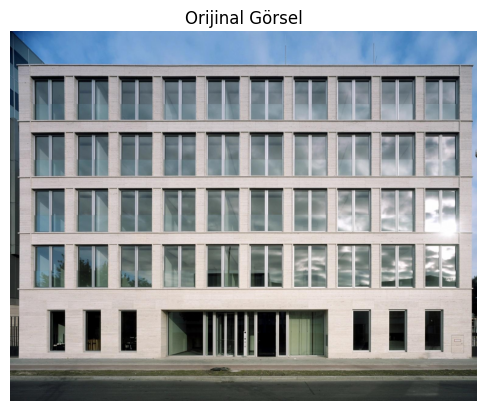

In [14]:
resim = cv2.imread("image09.jpeg")

plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Görsel")
plt.axis("off")
plt.show()

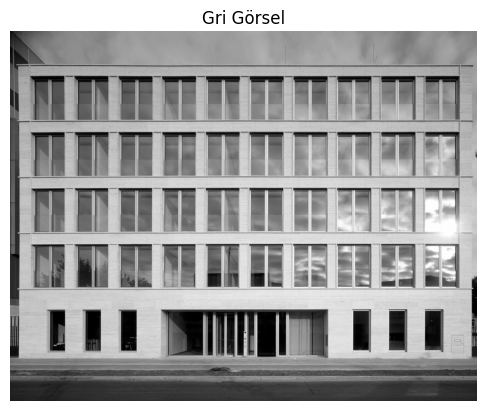

In [15]:
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)

plt.imshow(gri, cmap="gray")
plt.title("Gri Görsel")
plt.axis("off")
plt.show()

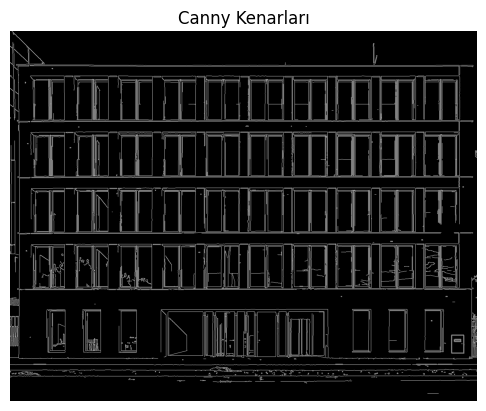

In [16]:
kenarlar = cv2.Canny(gri, 100, 200)

plt.imshow(kenarlar, cmap="gray")
plt.title("Canny Kenarları")
plt.axis("off")
plt.show()

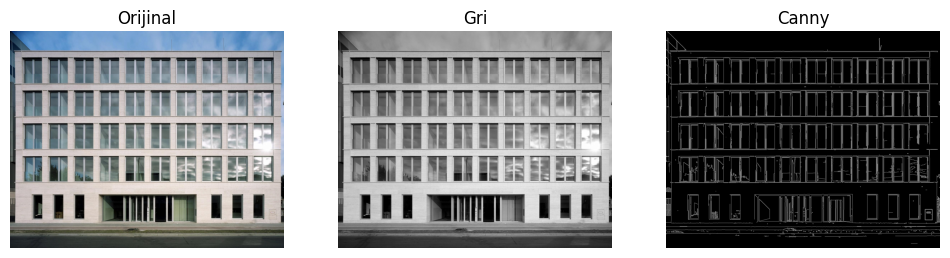

In [17]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Orijinal")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gri, cmap="gray")
plt.title("Gri")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(kenarlar, cmap="gray")
plt.title("Canny")
plt.axis("off")

plt.show()

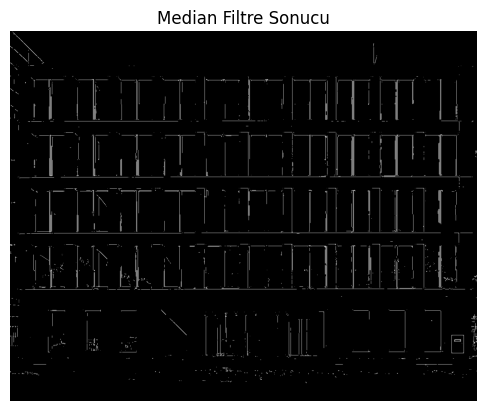

In [18]:
median = cv2.medianBlur(kenarlar, 3)

plt.imshow(median, cmap="gray")
plt.title("Median Filtre Sonucu")
plt.axis("off")
plt.show()

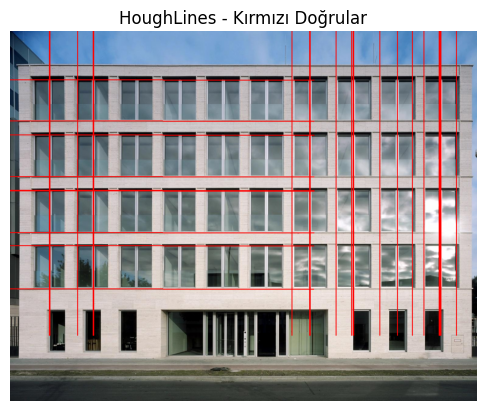

In [19]:
lines = cv2.HoughLines(median, 1, np.pi / 180, 70)

sonuc1 = resim.copy()

if lines is not None:
    for line in lines[:30]:
        rho, theta = line[0]

        a = np.cos(theta)
        b = np.sin(theta)

        x0 = a * rho
        y0 = b * rho

        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * a)

        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * a)

        cv2.line(sonuc1, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.imshow(cv2.cvtColor(sonuc1, cv2.COLOR_BGR2RGB))
plt.title("HoughLines - Kırmızı Doğrular")
plt.axis("off")
plt.show()

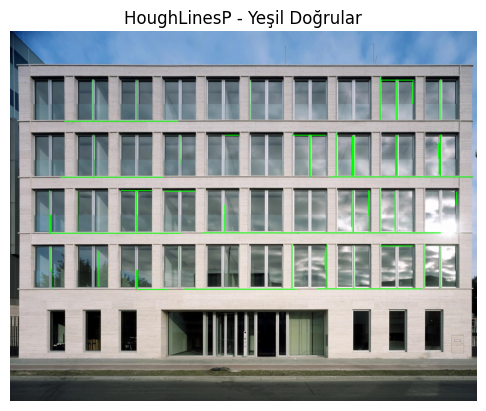

In [20]:
linesP = cv2.HoughLinesP(
    median,
    1,
    np.pi / 180,
    threshold=40,
    minLineLength=40,
    maxLineGap=10
)

sonuc2 = resim.copy()

if linesP is not None:
    for line in linesP[:60]:
        x1, y1, x2, y2 = line[0]

        cv2.line(sonuc2, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.imshow(cv2.cvtColor(sonuc2, cv2.COLOR_BGR2RGB))
plt.title("HoughLinesP - Yeşil Doğrular")
plt.axis("off")
plt.show()

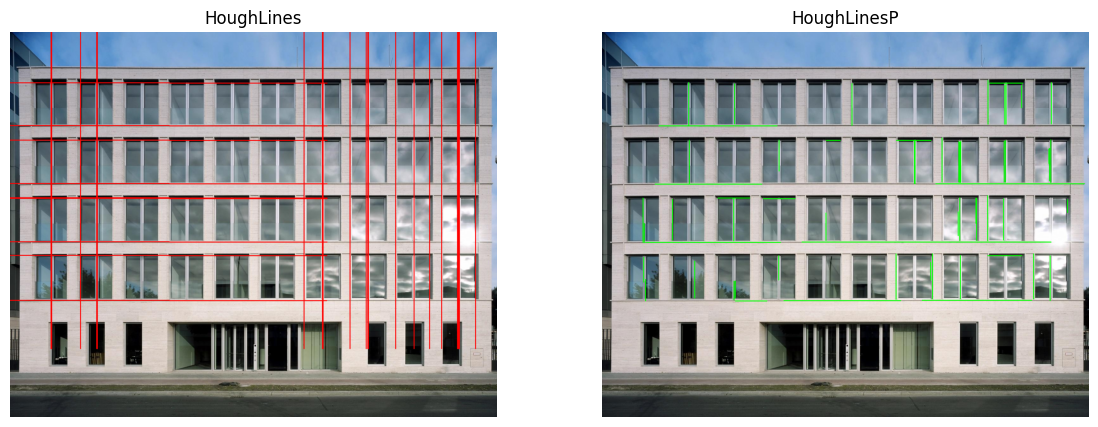

In [21]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(sonuc1, cv2.COLOR_BGR2RGB))
plt.title("HoughLines")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sonuc2, cv2.COLOR_BGR2RGB))
plt.title("HoughLinesP")
plt.axis("off")

plt.show()